# 第四轮：把论文方法变成同口径实验

**结论：通过升级门槛，采用本轮论文候选流程。当前推荐为 `add_age_spline_C0.01`。** 本轮登记 **51 个配置**，候选特征池共 **259 项**，各模型使用对应子集；训练比赛为 **33,833 场**。所有最终比较保持同样的 2,588 场 2023 比赛。

## 四条论文路线，分别复用了什么

| 论文路线 | 本轮实现 | 复现与改编边界 |
| --- | --- | --- |
| Angelini、Candila、De Angelis： [Weighted Elo](https://doi.org/10.1016/j.ejor.2021.04.011) | 历史比分的局/盘占比加权 Elo，保留相同动态 K 的普通 Elo 对照 | 按核对过的原方程实现权重；T−21、同日批量、场地评分银行和派生特征是项目适配，不复现论文原样本成绩或投注结果。 |
| Arcagni、Candila、Grassi： [eigenvector centrality](https://pmc.ncbi.nlm.nih.gov/articles/PMC8900648/) | 败者→胜者的时间加权网络与入向主特征向量 | 使用论文的双曲衰减和归一化中心性核心；伪链接正则、未知球员先验、仅历史节点及场地网络属于明确改编。 |
| Spanias、Knottenbelt：[low-level point model](https://doi.org/10.1093/imaman/dps010)，并核对作者学位论文和 O'Malley 概率示例 | 既有赛前发球能力 → 局、盘、抢七与整场概率 | 递推保持发球顺序；采用统一抢七规则和项目能力估计，未完整复现论文能力估计器或所有历史赛事决胜盘规则。 |
| Buhamra、Groll、Gerharz：[modern forecasting approaches](https://doi.org/10.1177/22150218251338954)，及相关增强变量研究 | 赛前年龄、距 30 岁/[28,32]区间距离、ATP 排名积分和缺失标记 | 借鉴已定义变量变换，未移植赔率或论文完整机器学习流程；30 岁是固定参考假设，不是从本数据证明的最优年龄。 |


各分支的公式、原始全文访问记录、数值例子与局限见 `docs/research/round4_protocol.md` 及对应方法文档。这里检验的是**来源明确的项目适配**，不是直接重现作者发表的整套实验。论文使用不同赛事、预测时点或信息条件时，其准确率不能直接与本表比较。

前两次运行均在本轮 2023 评分之前中断：首次发现 2019 年华盛顿站积分快照问题，随后全量审计又发现同站年龄混合日期问题。最终修复将该赛事年龄和积分同时视为缺失，再从头运行。仅年龄和仅积分两个诊断分支是在首次已见部分训练期结果后追加，属于明确记录的自适应补充，并非从最初就固定的独立试验。 对日期/属性快照已审计但缺少可信赛前年龄和积分的赛事，保留目标比赛并将相关属性设缺失；积分遮蔽 94 次球员出场，年龄遮蔽 94 次，使用固定填充值和缺失标记。

## 升级门槛比较的是当前第三轮流程

2020–2021 的向前折先选定 `without_margin_spline_C0.003`；2022 年新候选 log loss 为 **0.59594**，第三轮相同早期选择流程的参照为 **0.60113**，改善 **+0.00519**，要求至少 **0.001**。没有退回较弱的第一轮流程降低门槛。作出流程决定后，才用全部 2020–2022 开发折重选配置，并计算本轮 2023 分数。

**2022 和 2023 已被前轮使用，因此这仍然是后续探索。** 本轮评分前登记的规则有助于避免随结果改口，但不等于独立预注册或恢复未见验证数据。2024–2025 最终测试没有打开。

## 同一批 2023 比赛的比较

| 比较 | 2023 log loss ↓ | 准确率 |
| --- | ---: | ---: |
| 只用排名 (`rank_reference`) | 0.62980 | 63.37% |
| 第一轮最强线性模型 (`round1_best_single`) | 0.61056 | 65.26% |
| 第一轮冻结集成 (`round1_ensemble`) | 0.61153 | 65.07% |
| 第三轮此前推荐 (`round3_recommended`) | 0.61082 | 65.53% |
| 第三轮扩展线性对照 (`round3_linear`) | 0.61057 | 65.88% |
| 第四轮训练期选中候选 (`add_age_spline_C0.01`) | 0.60941 | 65.53% |

第四轮训练期选中候选相对第三轮推荐的 log-loss 改善为 **+0.00142**，准确率变化 **+0.00 个百分点**。按赛事开始日期分块的配对改善区间为 **[-0.00141, 0.00425]**。**区间跨过 0，不能据此确认优于第三轮此前推荐。** 负改善表示变差；区间还没有覆盖跨日期重复球员依赖。

全部保存比较中，2023 最低 log loss 是 `without_graph_spline_C0.01`（**0.60868**）；这个描述性排序不替代上面的门槛决定，不能据此宣布 SOTA。

## 添加与删除信息的控制比较

添加组对照固定 2009 训练起点、样条表示、3 年近期权重及相同 C，与第三轮对应配置比较；pooled CV 数值越正，加入该组后越好：

- **比分加权实力**：匹配样条设置的 pooled CV log-loss 改善范围 **[-0.00016, +0.00001]**，方向随C改变。
- **时间加权对手网络**：匹配样条设置的 pooled CV log-loss 改善范围 **[+0.00016, +0.00032]**，两种C下均改善。
- **逐分到整场概率**：匹配样条设置的 pooled CV log-loss 改善范围 **[+0.00003, +0.00011]**，两种C下均改善。
- **年龄与排名积分**：匹配样条设置的 pooled CV log-loss 改善范围 **[+0.00441, +0.00444]**，两种C下均改善。
- **仅年龄表示**：匹配样条设置的 pooled CV log-loss 改善范围 **[+0.00446, +0.00448]**，两种C下均改善。
- **仅排名积分**：匹配样条设置的 pooled CV log-loss 改善范围 **[-0.00002, +0.00002]**，方向随C改变。

在两种匹配 C 下，单独加入年龄的改善都大于单独加入积分；这些控制比较支持年龄表示是更强的来源，但不能把联合 profile 的全部增益因果归于年龄。

删除组对照固定相同 C 的 `all_papers` 样条模型，移除一个论文分支。Notebook 保留全部 **20 项精确设置配对**及 2020、2021、2022 各年变化。删除对照也采用“参考损失−删除后损失”的符号：正数表示删掉该组反而更好，负数表示删除后变差。仅年龄/仅积分诊断用于区分 profile 分支的来源，但两类信息可能互相补充，不能假设联合增益必然等于单独增益相加。分支相关时，单独加入和条件删除回答不同问题；这些是预测信息比较，不是因果贡献。

家族最终 2023 表独立展示训练期选中的线性、样条或树配置，不能把跨算法和重新选择正则后的差异当成同参数消融。全部失败候选与原始公式概率基准均保留。

## 复跑与交接

```bash
.venv/bin/python -m scripts.train_round4
.venv/bin/python -m scripts.report_round4
```

[执行 notebook](round4.ipynb)、[HTML](round4.html) 和 [比较图](results/round4/round4_comparison.png) 单独保存，不覆盖以前实验。`search_registry.json` 记录候选和各论文分支元数据，`temporal_cv.csv` 保存全部训练期结果，`frozen_selection.json` 保存升级门槛和最终配置，`validation_predictions.csv` 保存逐场概率，本地 `frozen_models.joblib` 保存模型与旧对照。

最终测试应独立核验后按冻结方案执行；也应保留第三轮推荐、旧强线性模型和本轮候选，避免把探索性小提升写成已确认的泛化结论。


## 完整 2023 对比

星号表示门槛决定的推荐，不是把验证排序第一名自动换成推荐。

,model,description,role,matches,mean_log_loss,accuracy,brier,pooled_2020_22_cv_log_loss
0,without_graph_spline_C0.01,All except opponent network · spline,Exploratory comparison,2588,0.60868,0.65417,0.21118,0.60350
1,all_papers_spline_C0.01,All paper families · spline,Exploratory comparison,2588,0.60873,0.65263,0.21123,0.60345
2,without_point_spline_C0.01,All except point-to-match model · spline,Exploratory comparison,2588,0.60887,0.65185,0.21129,0.60352
3,without_margin_spline_C0.01,All except weighted Elo · spline,Exploratory comparison,2588,0.60916,0.65649,0.21142,0.60323
4,add_profile_spline_C0.01,Add age and rank points · spline,Exploratory comparison,2588,0.60924,0.65456,0.21143,0.60326
5,add_age_spline_C0.01,Add age only · spline,Recommendation after Round 4 gate,2588,0.60941,0.65533,0.21149,0.60319
6,without_profile_spline_C0.01,All except age and rank points · spline,Exploratory comparison,2588,0.61012,0.65649,0.21186,0.60751
7,add_margin_spline_C0.01,Add weighted Elo · spline,Exploratory comparison,2588,0.61047,0.65611,0.21197,0.60782
8,round1_best_single,Round 1 best linear,Exploratory comparison,2588,0.61056,0.65263,0.21220,NaN
9,add_point_spline_C0.01,Add point-to-match model · spline,Exploratory comparison,2588,0.61056,0.65572,0.21201,0.60763


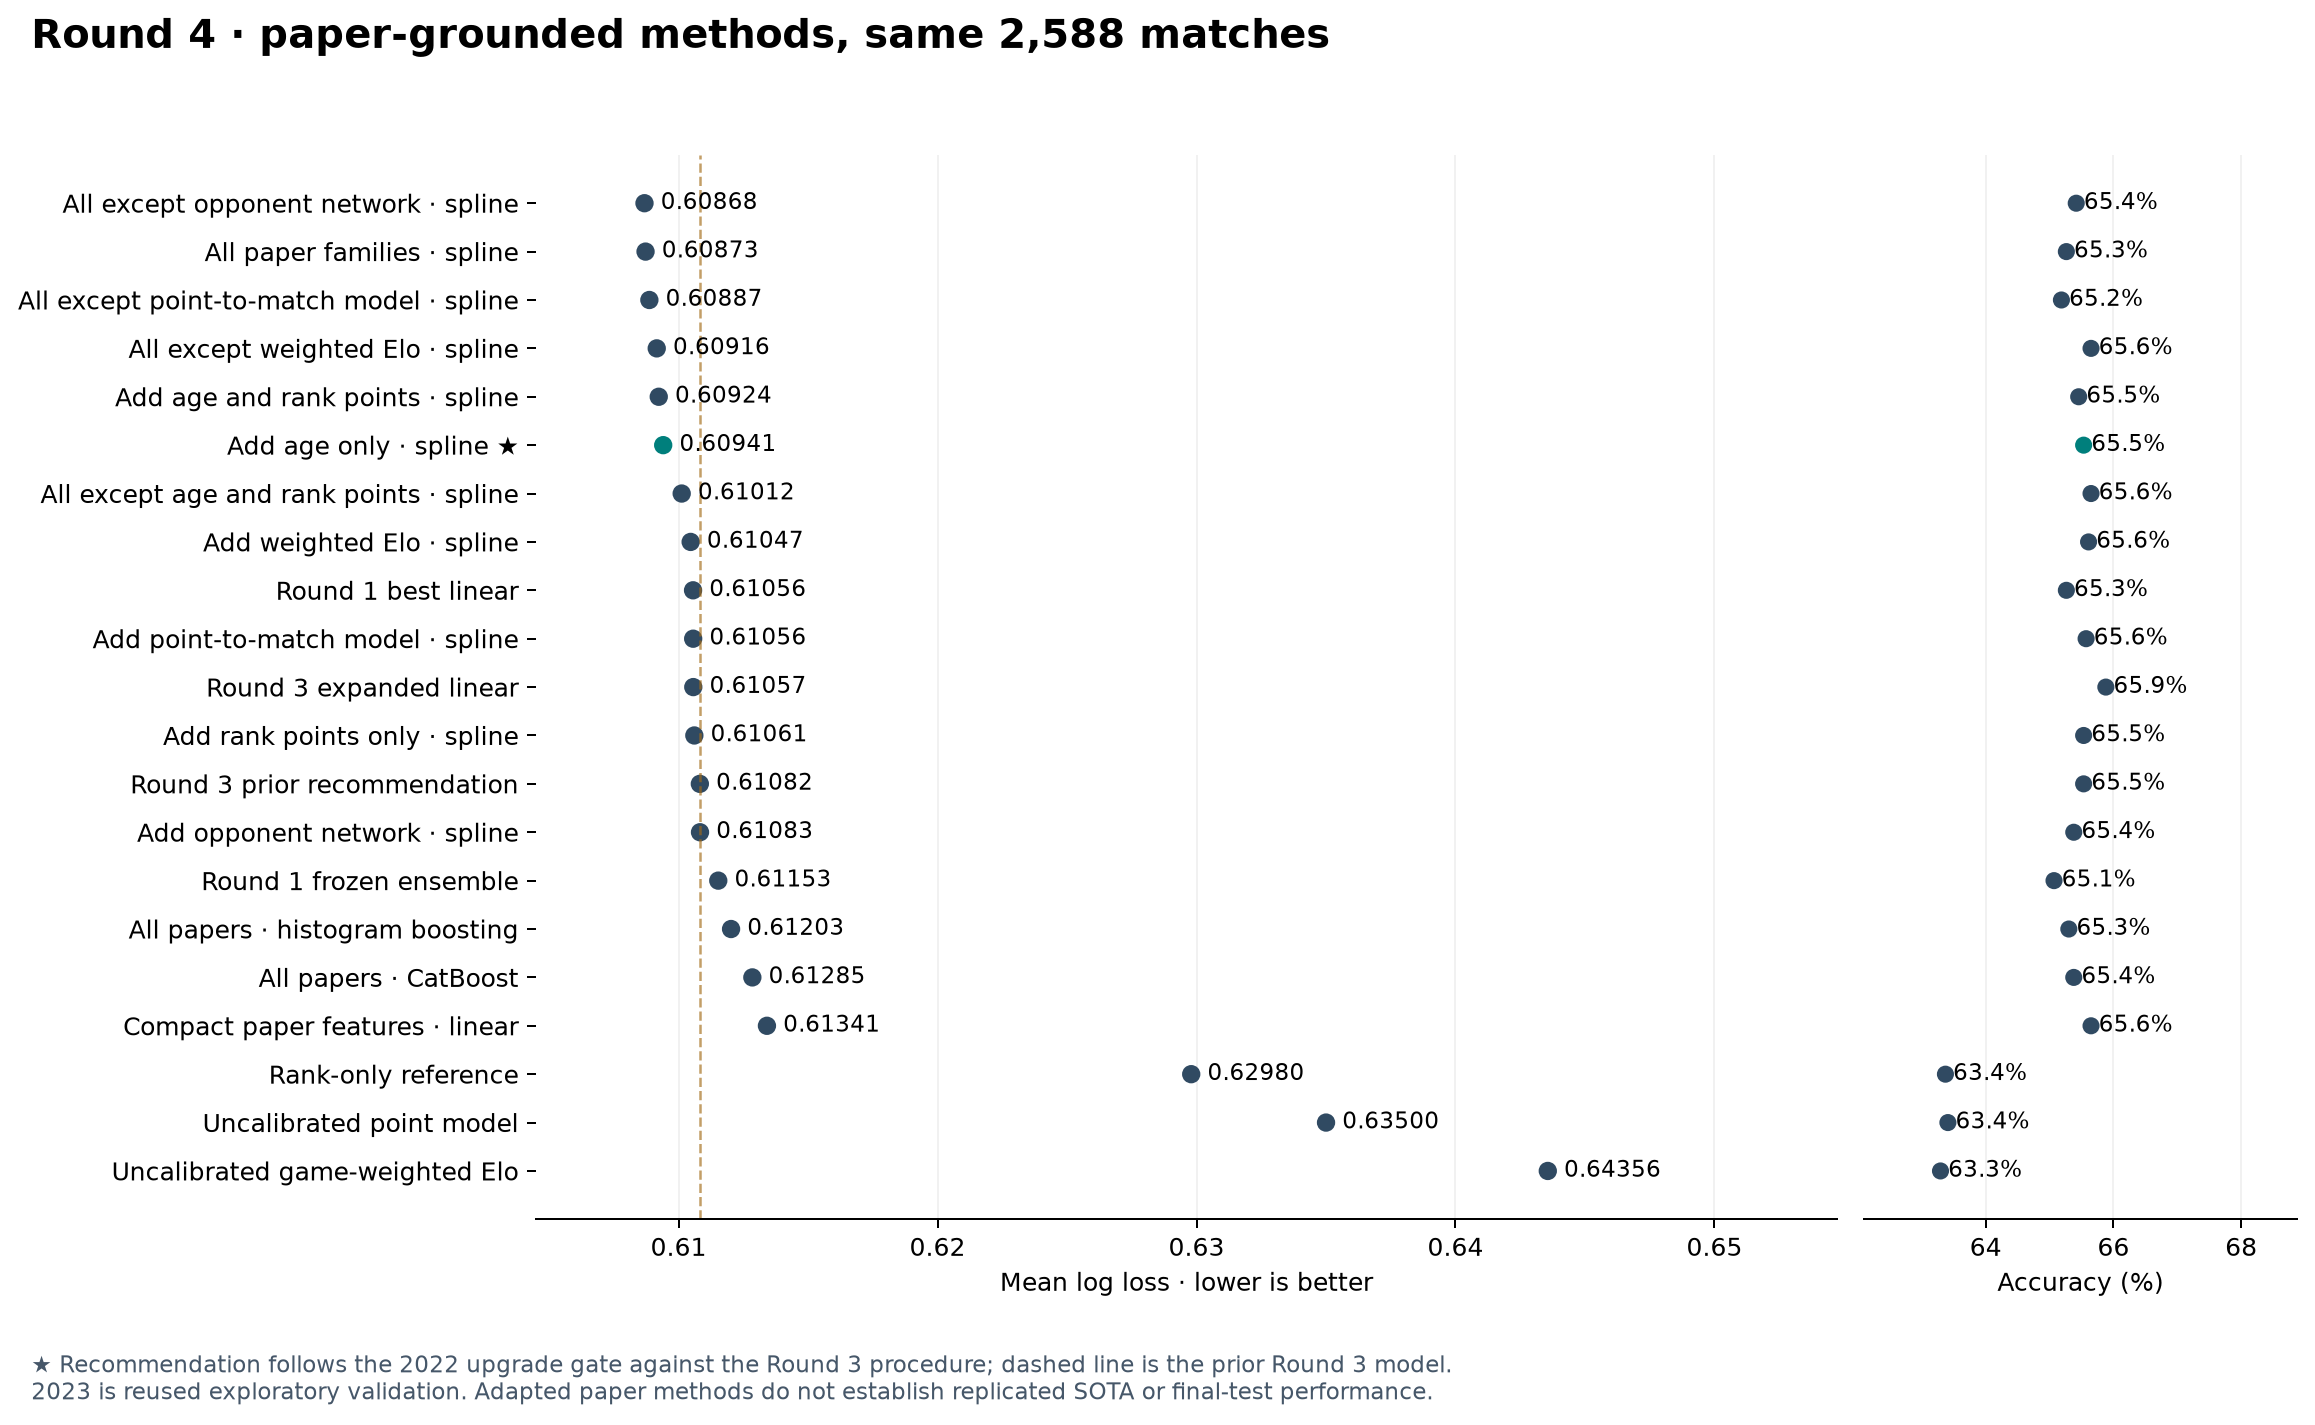

In [1]:
from IPython.display import display, Image
import pandas as pd
from scripts.report_round4 import load_results,comparison_table,family_table,matched_cv_controls,OUT
data=load_results()
pd.set_option('display.max_columns',None)
pd.set_option('display.precision',5)
display(comparison_table(data))
display(Image(filename=str(OUT/'round4_comparison.png')))

## 同设置添加/删除组 CV

正数统一表示候选比参考损失低；因此删除组行的正数表示删组后改善。仅比较相同样条、C、训练期与近期权重，完整保留逐年方向。

In [2]:
display(matched_cv_controls(data))

,comparison,group,C,reference,candidate,reduction_mean_log_loss,reduction_2020,reduction_2021,reduction_2022
0,add_group_to_round3,比分加权实力,0.003,history2009_odd_spline_C0.003_context1_half3.0...,add_margin_spline_C0.003,0.00001,0.00017,0.00006,-0.00011
1,remove_group_from_all,比分加权实力,0.003,all_papers_spline_C0.003,without_margin_spline_C0.003,0.00017,0.00025,0.00003,0.00025
2,add_group_to_round3,比分加权实力,0.010,history2009_odd_spline_C0.01_context1_half3.0_...,add_margin_spline_C0.01,-0.00016,0.00022,-0.00010,-0.00040
3,remove_group_from_all,比分加权实力,0.010,all_papers_spline_C0.01,without_margin_spline_C0.01,0.00022,0.00020,-0.00004,0.00048
4,add_group_to_round3,时间加权对手网络,0.003,history2009_odd_spline_C0.003_context1_half3.0...,add_graph_spline_C0.003,0.00032,0.00086,0.00030,0.00008
5,remove_group_from_all,时间加权对手网络,0.003,all_papers_spline_C0.003,without_graph_spline_C0.003,-0.00004,-0.00025,-0.00012,0.00012
6,add_group_to_round3,时间加权对手网络,0.010,history2009_odd_spline_C0.01_context1_half3.0_...,add_graph_spline_C0.01,0.00016,0.00049,0.00035,-0.00017
7,remove_group_from_all,时间加权对手网络,0.010,all_papers_spline_C0.01,without_graph_spline_C0.01,-0.00005,-0.00014,-0.00039,0.00031
8,add_group_to_round3,逐分到整场概率,0.003,history2009_odd_spline_C0.003_context1_half3.0...,add_point_spline_C0.003,0.00011,0.00016,0.00017,0.00002
9,remove_group_from_all,逐分到整场概率,0.003,all_papers_spline_C0.003,without_point_spline_C0.003,-0.00008,-0.00010,-0.00009,-0.00007


## 所有家族与候选

家族最终候选重新选择了模型种类或正则，因此此表属于模型家族比较，不是上述精确设置配对。

In [3]:
display(family_table(data))
display(data['cv'].sort_values('mean_log_loss'))
display(pd.DataFrame([{'branch':g,'features':len(cols)} for g,cols in data['registry']['feature_groups'].items()]))

,family,model,description,CV_log_loss,2023_log_loss,2023_accuracy
0,add_age,add_age_spline_C0.01,Add age only · spline,0.60319,0.60941,0.65533
13,without_margin,without_margin_spline_C0.01,All except weighted Elo · spline,0.60323,0.60916,0.65649
5,add_profile,add_profile_spline_C0.01,Add age and rank points · spline,0.60326,0.60924,0.65456
6,all_papers,all_papers_spline_C0.01,All paper families · spline,0.60345,0.60873,0.65263
12,without_graph,without_graph_spline_C0.01,All except opponent network · spline,0.60350,0.60868,0.65417
14,without_point,without_point_spline_C0.01,All except point-to-match model · spline,0.60352,0.60887,0.65185
8,paper_compact,paper_compact_linear_C0.01,Compact paper features · linear,0.60497,0.61341,0.65649
7,paper_catboost,papers_cat_d4,All papers · CatBoost,0.60525,0.61285,0.65379
9,paper_histboost,papers_hist_l15,All papers · histogram boosting,0.60666,0.61203,0.65301
1,add_graph,add_graph_spline_C0.01,Add opponent network · spline,0.60750,0.61083,0.65379


,name,family,mean_log_loss,2020,2021,2022
19,add_age_spline_C0.01,add_age,0.60319,0.60661,0.61048,0.59466
33,without_margin_spline_C0.01,without_margin,0.60323,0.60674,0.61041,0.59477
15,add_profile_spline_C0.01,add_profile,0.60326,0.60689,0.61075,0.59444
27,all_papers_spline_C0.01,all_papers,0.60345,0.60694,0.61037,0.59525
35,without_graph_spline_C0.01,without_graph,0.60350,0.60708,0.61075,0.59494
32,without_margin_spline_C0.003,without_margin,0.60351,0.60605,0.61022,0.59594
37,without_point_spline_C0.01,without_point,0.60352,0.60707,0.61046,0.59526
17,add_age_spline_C0.003,add_age,0.60361,0.60619,0.61025,0.59609
13,add_profile_spline_C0.003,add_profile,0.60362,0.60646,0.61041,0.59584
25,all_papers_spline_C0.003,all_papers,0.60367,0.60630,0.61026,0.59619


,branch,features
0,base,202
1,margin,22
2,graph,12
3,point,12
4,profile,11


## 门槛和条件不确定性

基准是第三轮当前推荐。区间不能修正重复查看验证年份和多轮设计选择带来的全部不确定性。

In [4]:
display(pd.DataFrame([data['frozen']['procedure_gate']]))
display(pd.DataFrame([{'model':n,'loss_reduction':v['mean_log_loss_reduction'],'lower95':v['ci95'][0],'upper95':v['ci95'][1]} for n,v in data['summary']['comparisons_vs_round3'].items()]).sort_values('loss_reduction',ascending=False))
assert data['summary']['final_test_evaluated'] is False
print('2024–2025 final holdout remains unopened.')

,procedure,early_selected,reference_2022_loss,candidate_2022_loss,absolute_improvement,required_improvement,selection_seasons,gate_season
0,adopt_paper_model,without_margin_spline_C0.003,0.60113,0.59594,0.00519,0.001,"[2020, 2021]",2022


,model,loss_reduction,lower95,upper95
10,without_graph_spline_C0.01,2.13765e-03,-0.00079,0.00502
6,all_papers_spline_C0.01,2.09708e-03,-0.00105,0.00511
12,without_point_spline_C0.01,1.94939e-03,-0.00117,0.00500
11,without_margin_spline_C0.01,1.66478e-03,-0.00126,0.00454
5,add_profile_spline_C0.01,1.58705e-03,-0.00121,0.00440
0,add_age_spline_C0.01,1.41542e-03,-0.00141,0.00425
13,without_profile_spline_C0.01,7.01182e-04,-0.00044,0.00188
2,add_margin_spline_C0.01,3.55017e-04,-0.00071,0.00137
17,round1_best_single,2.62590e-04,-0.00219,0.00267
3,add_point_spline_C0.01,2.57924e-04,0.00011,0.00040


2024–2025 final holdout remains unopened.
